# 01 - Scenario di riferimento e verifica nominale (adult#001)

**Obiettivo.** Definire lo scenario di riferimento, verificare che l'anello chiuso sia stabile a digiuno e osservare la
risposta a un pasto non annunciato da 60 g.

**Controllori** (codice in `aid_sim.py`, configurazioni in `A.CFG`):
1. **PID**: regolatore a tempo discreto `u = u_b + Kp e + Ki I + Kd dy/dt` con anti-windup (limiti dell'integrale
   legati al basale e integrazione condizionata) e pendenza CGM stimata ai minimi quadrati sugli ultimi 5 campioni.
2. **PID+IOB+PLGS** (proposto): lo stesso PID con tetto sull'insulina attiva stimata e sospensione predittiva.
3. **PID senza AW**: il PID della prima versione (`Ki = 5e-6`), con un clamp dell'integrale così largo da non intervenire mai.
   Serve solo a mostrare l'effetto del windup.

**Protocollo.** La simulazione parte alle 00:00 del giorno precedente con il controllore già attivo; il giorno
precedente e le ore 00:00-08:00 (32 h in tutto) servono ad assestare l'anello sul target e non entrano nelle metriche.
La finestra di analisi va dalle 08:00 alle 24:00 del giorno di analisi.

**Taratura.** `Kp = 1e-4`, `Ki = 3e-7`, `Kd = 2e-3`. Con il `Ki = 5e-6` della versione precedente l'anello oscillava
anche a digiuno (periodo di circa 10-12 h, fino a 64-165 mg/dL su adult#003): la sezione 2.1 lo verifica su 10 adulti.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import aid_sim as A, notebook_utils as U
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 110)
SEED = 1                                  # seme del rumore del sensore (uguale per tutti i controllori)
COL = {"PID senza AW": "tab:gray", "PID": "tab:red", "PID cons.": "tab:orange",
       "PID+PLGS": "tab:green", "PID+IOB": "tab:purple", "PID+IOB+PLGS": "tab:blue"}
print("Versioni delle librerie usate:"); display(U.library_versions())

Versioni delle librerie usate:


,Pacchetto,Versione
0,Python,3.13.16
1,simglucose,0.2.11
2,numpy,2.4.4
3,scipy,1.17.1
4,pandas,3.0.2
5,matplotlib,3.10.8


In [2]:
def finestra(df):
    """Solo la finestra di analisi (08:00-24:00): l'assestamento 00:00-08:00 non entra né nei grafici né nelle metriche."""
    return df[df.t_h >= A.WARMUP_H]

def decora(ax, meal_h=A.MEAL_CLOCK_H, banda=True):
    """Linea del pasto e griglia; banda 70-180 mg/dL solo sui pannelli di glicemia."""
    if banda:
        ax.axhspan(70, 180, color="green", alpha=0.12)
    ax.axvline(meal_h, color="k", ls=":", lw=1.2); ax.grid(ls=":", alpha=0.5)

def tabella(risultati, chiavi):
    """risultati: dict {chiave: DataFrame}; chiavi: nomi delle colonne-indice per la tabella."""
    rows = []
    for k, df in risultati.items():
        k = k if isinstance(k, tuple) else (k,)
        rows.append({**dict(zip(chiavi, k)), **{m: round(float(v), 1) for m, v in A.metrics(df).items()}})
    return pd.DataFrame(rows)

## 1. Configurazione
### 1.1 Scenario: condizioni iniziali, durata, passo, pasto, seme

In [3]:
PAZIENTE = "adult#001"
ub = U.initial_conditions(PAZIENTE, SEED)["ub"]
display(U.scenario_table(PAZIENTE, 60.0, SEED))

,Voce,Valore,Unita'
0,Paziente virtuale,adult#001,-
1,Peso corporeo BW,102.3,kg
2,Glicemia basale di equilibrio Gb,138.6,mg/dL
3,Fabbisogno basale nominale u_b,1.267,U/h
4,Sensore CGM,Dexcom (rumore di simglucose),-
5,Pompa di infusione,Insulet,-
6,Seme casuale del sensore,1,-
7,Inizio simulazione,00:00 del giorno precedente (24 h prima),ora del giorno
8,Assestamento escluso dalle metriche,giorno precedente + 00:00-08:00 (32 h),-
9,Finestra di analisi,08:00-24:00,ora del giorno


### 1.2 Parametri e vincoli dei controllori (con unità di misura)

In [4]:
for n in ["PID", "PID+IOB+PLGS", "PID senza AW"]:
    print(n, "- argomenti passati ad AIDController:", A.CFG[n]); display(U.controller_table(A.CFG[n], ub))

PID - argomenti passati ad AIDController: {}


,Parametro,Valore,Unita',Significato
0,target,120.0,mg/dL,Glicemia obiettivo del regolatore
1,kp,0.0001,U/min per mg/dL,Guadagno proporzionale
2,ki,0.0,U/min per (mg/dL*min),Guadagno integrale
3,kd,0.002,U/min per (mg/dL/min),Guadagno derivativo sulla pendenza CGM
4,n_slope,5,campioni,Campioni CGM usati per stimare la pendenza ai minimi quadrati
5,aw_frac,1.0,adimensionale,Anti-windup: Ki*I_max = aw_frac * basale
6,aw_frac_low,0.25,adimensionale,Anti-windup: Ki*I_min = -aw_frac_low * basale
7,freeze,True,-,Integrazione condizionata quando l'uscita è limitata
8,use_iob,False,-,Attiva il tetto sull'insulina attiva (IOB)
9,iob_alpha,0.75,adimensionale,Tetto IOB = iob_alpha * basale orario


PID+IOB+PLGS - argomenti passati ad AIDController: {'use_iob': True, 'use_plgs': True}


,Parametro,Valore,Unita',Significato
0,target,120.0,mg/dL,Glicemia obiettivo del regolatore
1,kp,0.0001,U/min per mg/dL,Guadagno proporzionale
2,ki,0.0,U/min per (mg/dL*min),Guadagno integrale
3,kd,0.002,U/min per (mg/dL/min),Guadagno derivativo sulla pendenza CGM
4,n_slope,5,campioni,Campioni CGM usati per stimare la pendenza ai minimi quadrati
5,aw_frac,1.0,adimensionale,Anti-windup: Ki*I_max = aw_frac * basale
6,aw_frac_low,0.25,adimensionale,Anti-windup: Ki*I_min = -aw_frac_low * basale
7,freeze,True,-,Integrazione condizionata quando l'uscita è limitata
8,use_iob,True,-,Attiva il tetto sull'insulina attiva (IOB)
9,iob_alpha,0.75,adimensionale,Tetto IOB = iob_alpha * basale orario


PID senza AW - argomenti passati ad AIDController: {'ki': 5e-06, 'i_min': -2000.0, 'i_max': 10000.0, 'freeze': False}


,Parametro,Valore,Unita',Significato
0,target,120.0,mg/dL,Glicemia obiettivo del regolatore
1,kp,0.0001,U/min per mg/dL,Guadagno proporzionale
2,ki,0.000005,U/min per (mg/dL*min),Guadagno integrale
3,kd,0.002,U/min per (mg/dL/min),Guadagno derivativo sulla pendenza CGM
4,n_slope,5,campioni,Campioni CGM usati per stimare la pendenza ai minimi quadrati
5,aw_frac,1.0,adimensionale,Anti-windup: Ki*I_max = aw_frac * basale
6,aw_frac_low,0.25,adimensionale,Anti-windup: Ki*I_min = -aw_frac_low * basale
7,freeze,False,-,Integrazione condizionata quando l'uscita è limitata
8,use_iob,False,-,Attiva il tetto sull'insulina attiva (IOB)
9,iob_alpha,0.75,adimensionale,Tetto IOB = iob_alpha * basale orario


### Unità di misura delle variabili salvate
| Variabile | Unità | Significato |
|---|---|---|
| `t_h` | h | ora del giorno di analisi (la simulazione parte alle 00:00 del giorno precedente, `t_h` = -24) |
| `CGM` | mg/dL | misura del sensore, con rumore: è l'unica grandezza vista dal controllore |
| `BG` | mg/dL | glicemia plasmatica del modello UVa/Padova (Gp/Vg), usata per le metriche |
| `Gsub` | mg/dL | glicemia sottocutanea senza rumore (`info['bg']` di simglucose) |
| `Insulin_Uh` | U/h | velocità di infusione comandata |
| `IOB` | U | insulina attiva netta stimata dal controllore (eccesso rispetto al basale) |
| `IOB_vero` | U | insulina sottocutanea netta del modello (Isc1 + Isc2 meno l'equilibrio basale) |
| `Vincolo` | - | vincolo attivo nel passo: `iob`, `plgs`, `sat_alta`, `sat_bassa` o vuoto |

Metriche: TIR, TAR, TBR in % del tempo nella finestra 08:00-24:00; `TIR_post6h` nelle 6 h dopo il pasto;
`TBR_tardivo` dalle 3 h dopo il pasto alle 24:00; picco e nadir in mg/dL; `insulina_tot` in U nella finestra.

## 2. Verifica nominale a digiuno (0 g)
Senza pasto la glicemia deve assestarsi sul target e restare nell'intervallo 70-180 mg/dL.

,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,PID,100.0,0.0,0.0,0.0,0.0,0.0,100.0,118.1,116.1,23.3,40.3,13.6,0.0,0.0,0.0,0.0,8.2,0.1
1,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,100.0,118.8,116.8,23.5,29.7,11.7,0.0,0.0,4.0,2.0,12.9,0.3


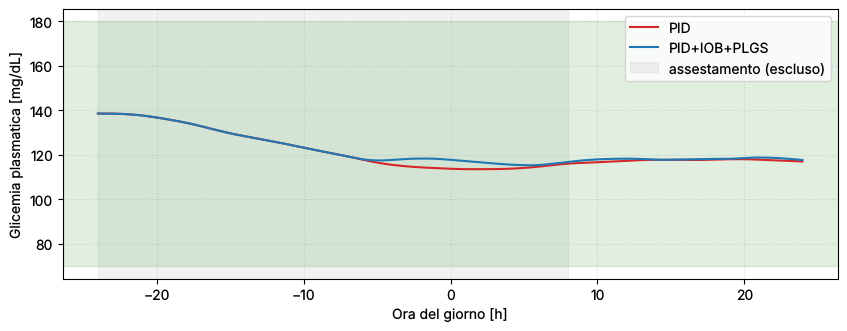

In [5]:
res0 = {n: A.simulate(PAZIENTE, 0.0, A.CFG[n], seed=SEED)[0] for n in ["PID", "PID+IOB+PLGS"]}
display(tabella(res0, ["Controllore"]))
fig, ax = plt.subplots(figsize=(10, 3.5))
for n, df in res0.items():
    ax.plot(df.t_h, df.BG, color=COL[n], label=n)
ax.axvspan(-A.PRE_H, A.WARMUP_H, color="gray", alpha=0.1, label="assestamento (escluso)")
ax.axhspan(70, 180, color="green", alpha=0.12); ax.grid(ls=":", alpha=0.5)
ax.set_xlabel("Ora del giorno [h]"); ax.set_ylabel("Glicemia plasmatica [mg/dL]"); ax.legend(); plt.show()

### 2.1 Verifica nominale con criterio esplicito (10 adulti, 3 giorni di digiuno)
Senza rumore del sensore, così che l'ampiezza misuri l'oscillazione propria dell'anello e non il rumore.
**Criterio:** nell'ultimo giorno la glicemia plasmatica deve oscillare meno di `A.AMPIEZZA_MAX` = 5 mg/dL e dalle 08:00
del giorno di analisi non deve scendere sotto 70 mg/dL. Si confronta la taratura attuale con quella precedente (`Ki = 5e-6`).

In [6]:
import run_campaign as RC
from multiprocessing import Pool
with Pool() as pool:
    dig = dict(pool.map(RC._digiuno, [(p, n) for p in RC.POPOLAZIONE for n in RC.DIGIUNO]))
V = pd.DataFrame([{"Paziente": p, "Controllore": n, **{k: (round(v, 1) if isinstance(v, float) else v)
                   for k, v in dig[(p, n)][0].items()}} for n in RC.DIGIUNO for p in RC.POPOLAZIONE])
display(V)
print(V.groupby("Controllore", sort=False).superata.agg(["sum", "count"]).rename(columns={"sum": "superata", "count": "pazienti"}))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for j, n in enumerate(["PID (Ki precedente 5e-6)", "PID"]):
    for p in RC.POPOLAZIONE:
        d = dig[(p, n)][1]; ax[j].plot(d.t_h, d.BG, lw=1, label=p)
    ax[j].axhspan(70, 180, color="green", alpha=0.12); ax[j].axhline(120, color="k", ls="--", lw=0.8)
    ax[j].axvspan(-A.PRE_H, A.WARMUP_H, color="gray", alpha=0.1); ax[j].grid(ls=":", alpha=0.5)
    ax[j].set_title(n); ax[j].set_xlabel("Ore dalla mezzanotte del giorno di analisi [h]")
ax[0].set_ylabel("Glicemia plasmatica [mg/dL]"); ax[1].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

,Paziente,Controllore,ampiezza_ultimo_giorno,media_ultimo_giorno,min_dalle_08,max_dalle_08,TBR_dalle_08,superata
0,adult#001,PID,0.2,120.0,119.2,120.2,0.0,True
1,adult#002,PID,0.2,119.9,119.6,120.0,0.0,True
2,adult#003,PID,0.1,120.0,120.0,120.6,0.0,True
3,adult#004,PID,0.0,120.0,120.0,120.0,0.0,True
4,adult#005,PID,0.7,120.4,120.2,122.4,0.0,True
5,adult#006,PID,0.0,120.0,119.9,120.2,0.0,True
6,adult#007,PID,0.0,120.0,120.0,120.0,0.0,True
7,adult#008,PID,0.0,120.0,120.0,120.1,0.0,True
8,adult#009,PID,0.0,120.0,119.5,120.0,0.0,True
9,adult#010,PID,0.5,120.3,120.1,121.9,0.0,True


                          superata  pazienti
Controllore                                 
PID                             10        10
PID (Ki precedente 5e-6)         0        10
PID+IOB+PLGS                    10        10


## 3. Pasto non annunciato da 60 g alle 12:00

In [7]:
res = {n: A.simulate(PAZIENTE, 60.0, A.CFG[n], seed=SEED)[0] for n in ["PID senza AW", "PID", "PID+IOB+PLGS"]}
fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for n, df in res.items():
    d = finestra(df)
    ax[0].plot(d.t_h, d.BG, color=COL[n], label=n)
    ax[1].plot(d.t_h, d.Insulin_Uh, color=COL[n], drawstyle="steps-post")
    ax[2].plot(d.t_h, d.IOB, color=COL[n], label=f"{n} (stimato)")
    ax[2].plot(d.t_h, d.IOB_vero, color=COL[n], ls="--", lw=1, label=f"{n} (modello)")
ax[1].axhline(ub * 60, color="gray", ls=":", label="basale"); ax[1].legend()
ax[2].axhline(A.IOB_ALPHA * ub * 60, color="gray", ls="-.", label="tetto IOB")
decora(ax[0]); decora(ax[1], banda=False); decora(ax[2], banda=False)
ax[0].set_ylabel("Glicemia plasmatica [mg/dL]"); ax[0].legend()
ax[1].set_ylabel("Infusione [U/h]"); ax[2].set_ylabel("IOB netto [U]"); ax[2].legend(fontsize=7, ncol=2)
ax[2].set_xlabel("Ora del giorno [h]"); ax[2].set_xlim(A.WARMUP_H, A.ANALYSIS_END_H); plt.tight_layout(); plt.show()

In [8]:
T = tabella(res, ["Controllore"]); display(T)
print("Passi con vincolo attivo (finestra di analisi):")
display(pd.DataFrame({n: finestra(df).Vincolo.replace("", "nessuno").value_counts() for n, df in res.items()}).fillna(0).astype(int))

,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,TIR_post6h,picco,nadir,insulina_tot,IAE,IAE_post6h,IAE_range,t_rientro,n_commut,n_sosp,TV_u,std_u
0,PID senza AW,40.6,26.6,0.0,32.8,14.4,36.7,29.2,225.0,35.5,38.4,913.4,420.0,189.2,NaN,0.0,0.0,13.7,1.8
1,PID,75.0,25.0,0.0,0.0,0.0,0.0,33.3,197.3,90.8,28.7,460.5,342.1,27.3,5.0,0.0,0.0,8.5,0.3
2,PID+IOB+PLGS,74.7,25.3,0.0,0.0,0.0,0.0,32.5,196.8,98.8,27.7,438.1,342.8,26.4,5.0,62.0,0.0,56.8,0.3


Passi con vincolo attivo (finestra di analisi):


,PID senza AW,PID,PID+IOB+PLGS
Vincolo,,,
iob,0,0,31
nessuno,320,320,289


## 4. Lettura dei risultati (calcolata dalla tabella)

In [9]:
for n in T.Controllore:
    r = T[T.Controllore == n].iloc[0]
    print(f"{n:13s} TIR {r.TIR:5.1f} % | TAR {r.TAR:5.1f} % | TBR {r.TBR:5.1f} % (tardivo {r.TBR_tardivo:5.1f} %) | "
          f"picco {r.picco:5.0f} | nadir {r.nadir:5.0f} mg/dL | insulina {r.insulina_tot:5.1f} U")

PID senza AW  TIR  40.6 % | TAR  26.6 % | TBR  32.8 % (tardivo  36.7 %) | picco   225 | nadir    36 mg/dL | insulina  38.4 U
PID           TIR  75.0 % | TAR  25.0 % | TBR   0.0 % (tardivo   0.0 %) | picco   197 | nadir    91 mg/dL | insulina  28.7 U
PID+IOB+PLGS  TIR  74.7 % | TAR  25.3 % | TBR   0.0 % (tardivo   0.0 %) | picco   197 | nadir    99 mg/dL | insulina  27.7 U


**Note per l'interpretazione.**
- Il picco postprandiale dipende soprattutto dai ritardi di misura e di assorbimento dell'insulina sottocutanea: un
  controllore senza annuncio del pasto può ridurlo poco.
- Il confronto `PID senza AW` / `PID` isola l'effetto del windup dell'integratore: con un clamp troppo largo l'azione
  integrale continua a crescere durante l'iperglicemia e l'insulina accumulata provoca l'ipoglicemia tardiva.
- Il confronto `PID` / `PID+IOB+PLGS` isola l'effetto del tetto IOB e della sospensione predittiva, a parità di tutto il resto.
- Le linee tratteggiate confrontano l'IOB stimato dal controllore con l'insulina sottocutanea netta del modello:
  la differenza misura quanto è approssimato lo stimatore a due compartimenti con τ = 50 min.